In [3]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import gaussian_kde
# Import the actual, correct NSE calculation function

# python src/main.py evaluate --run_dir runs/run_2403_0211_seed401115 --camels_root "F:/Data/CAMEL_SI/CAMELS_US/" --gpu -1
# python src/main.py evaluate --run_dir runs/run_1303_1555_seed950317 --camels_root "F:/Data/CAMEL_SI/CAMELS_US/" --gpu -1

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# training:

In [ ]:
# python src/main.py train --family ft --thresh_file data/thresholds.parquet   --camels_root /scratch/hdagne1/conus-national-low-flow-thresholds-lstm/data/CAMELS_US/   --concat_static True --gpu 0 --seed 200 --num_workers 8

# Evaluating 

In [1]:
# python src\main.py evaluate --run_dir runs\run_2109_1000_ft_seed200 --camels_root "F:/Data/CAMEL_SI/CAMELS_US/" --gpu -1 --num_workers 0

In [5]:
thresholds = pd.read_parquet("/scratch/hdagne1/conus-national-low-flow-thresholds-lstm/data/thresholds.parquet")

In [ ]:
import tempfile
import xarray as xr
import pandas as pd
import requests
import geopandas as gpd

url = (
    "https://www.hydroshare.org/resource/658c359b8c83494aac0f58145b1b04e6/"
    "data/contents/camels_attributes_v2.0.feather"
)

tmp = tempfile.NamedTemporaryFile(suffix=".feather", delete=False)
tmp.write(requests.get(url).content)
basins = gpd.read_feather(tmp.name).reset_index()
basins['aridity']

0      0.630559
1      0.587356
2      0.624111
3      0.587950
4      0.628929
         ...   
666    0.627228
667    0.501305
668    0.386610
669    1.195390
670    0.410302
Name: aridity, Length: 671, dtype: float64

# Spatial Maps : For selected Basins:

C:\Users\hdagne1\AppData\Local\Temp\ipykernel_29188\1619522933.py:6: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  CAMELS_LongTerm_Final_vars_all['geometry_points'] = CAMELS_LongTerm_Final_vars_all['geometry'].centroid


Training set: (469, 64)
Validation set: (101, 64)
Testing set: (101, 64)


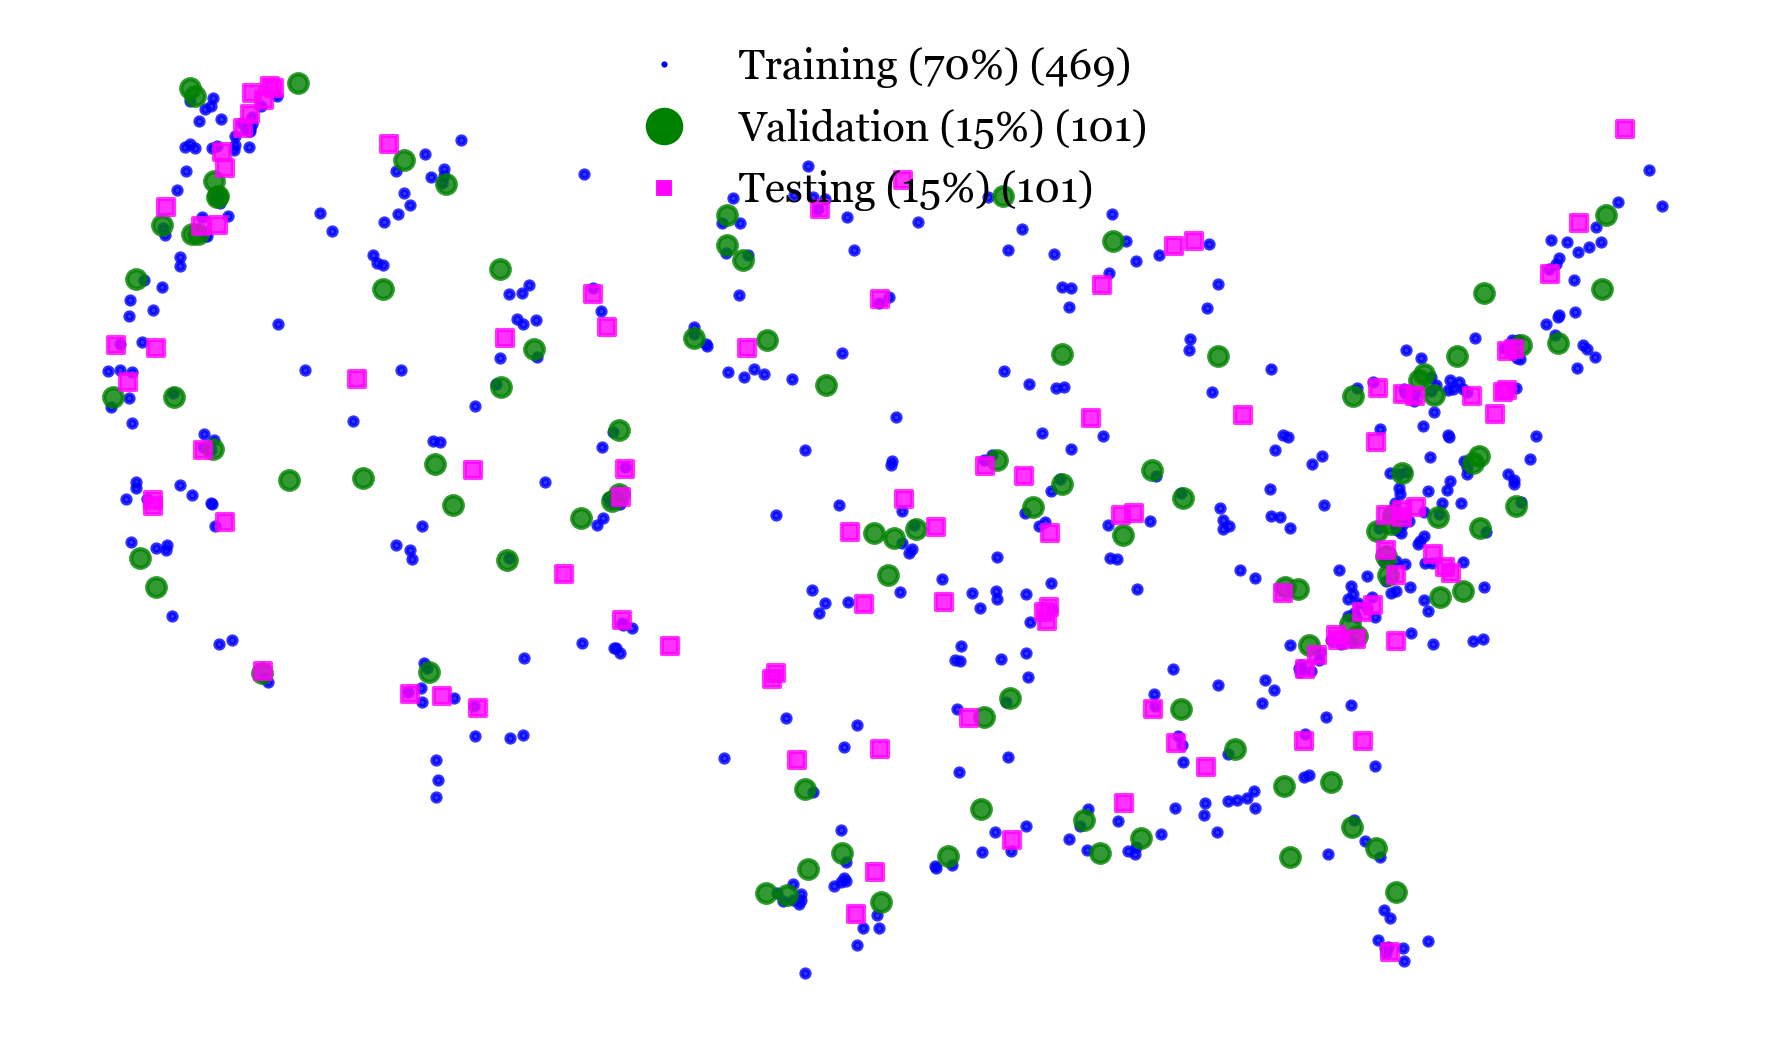

In [4]:
from sklearn.model_selection import train_test_split
plt.rcParams['font.family'] = 'Georgia'

CAMELS_LongTerm_Final_vars_all = basins.copy()

CAMELS_LongTerm_Final_vars_all['geometry_points'] = CAMELS_LongTerm_Final_vars_all['geometry'].centroid 
CAMELS_LongTerm_Final_vars_all = CAMELS_LongTerm_Final_vars_all.set_geometry('geometry_points')
CAMELS_LongTerm_Final_vars_all = CAMELS_LongTerm_Final_vars_all.drop(columns=['geometry']) 
CAMELS_LongTerm_Final_vars_all.head()



CAMELS_LongTerm_Final_vars_all['gauge_lat'] = CAMELS_LongTerm_Final_vars_all['geometry_points'].apply(lambda x: x.y)  
CAMELS_LongTerm_Final_vars_all['gauge_lon'] = CAMELS_LongTerm_Final_vars_all['geometry_points'].apply(lambda x: x.x)

# Define function to perform stratified spatial splitting
def spatial_split(df, train_size=0.7, val_size=0.15, test_size=0.15, random_state=42):
    """
    Function to split the dataframe into training, validation, and testing sets considering spatial distribution.
    """

    df['lat_bin'] = pd.qcut(df['gauge_lat'], q=4, labels=False)  
    df['lon_bin'] = pd.qcut(df['gauge_lon'], q=4, labels=False) 
    df['spatial_bin'] = df['lat_bin'].astype(str) + "_" + df['lon_bin'].astype(str)


    train_df, temp_df = train_test_split(
        df, test_size=(val_size + test_size), stratify=df['spatial_bin'], random_state=random_state
    )
    
    val_df, test_df = train_test_split(
        temp_df, test_size=test_size / (val_size + test_size), stratify=temp_df['spatial_bin'], random_state=random_state
    )

    return train_df, val_df, test_df

train_df, val_df, test_df = spatial_split(CAMELS_LongTerm_Final_vars_all)
print(f"Training set: {train_df.shape}")
print(f"Validation set: {val_df.shape}")
print(f"Testing set: {test_df.shape}")

fig, ax = plt.subplots(figsize=(6, 4), dpi=300)
markers = ['.', 'o', 's'] 
colors = ['blue', 'green', 'magenta']  

# states.boundary.to_crs(5070).plot(ax=ax, edgecolor='black', linewidth=0.3)
train_df.to_crs(5070).plot(
    ax=ax, 
    color=colors[0],  
    markersize=15,
    alpha=0.8, 
    marker=markers[0], 
    legend=False
)

val_df.to_crs(5070).plot(
    ax=ax, 
    color=colors[1],  
    markersize=20, 
    alpha=0.8,
    marker=markers[1],  
    legend=False
)

test_df.to_crs(5070).plot(
    ax=ax, 
    color=colors[2],  
    markersize=15, 
    alpha=0.8,
    marker=markers[2], 
    legend=False
)

ax.set_axis_off()
handles = [
    plt.Line2D([0], [0], marker=markers[0], color='w', markerfacecolor=colors[0], markersize=5, label='Training (70%) (469)'),
    plt.Line2D([0], [0], marker=markers[1], color='w', markerfacecolor=colors[1], markersize=10, label='Validation (15%) (101)'),
    plt.Line2D([0], [0], marker=markers[2], color='w', markerfacecolor=colors[2], markersize=5, label='Testing (15%) (101)')
]
ax.legend(
    handles=handles, 
    loc='upper center', 
    fontsize=10,
    frameon=False, 
    # fontweight='bold',
    bbox_to_anchor=(0.5, 1.03)  # Move legend slightly above the plot
)

# Save the figure
# fig.savefig('catchment_splitting.png', dpi=500, facecolor='white')

# Show the figure
plt.tight_layout()
plt.show()


In [5]:
states_all = gpd.read_file(r'F:\Data\Mopex_Boundaries\CONUS_shape/States_shapefile.shp').to_crs(5070)
states = states_all[~states_all['State_Name'].isin(['ALASKA', 'HAWAII'])]

Total selected basins: 119
Training set: (83, 64)
Testing set: (36, 64)


C:\Users\hdagne1\AppData\Local\Temp\ipykernel_29188\484782673.py:12: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  df['geometry_points'] = df['geometry'].centroid


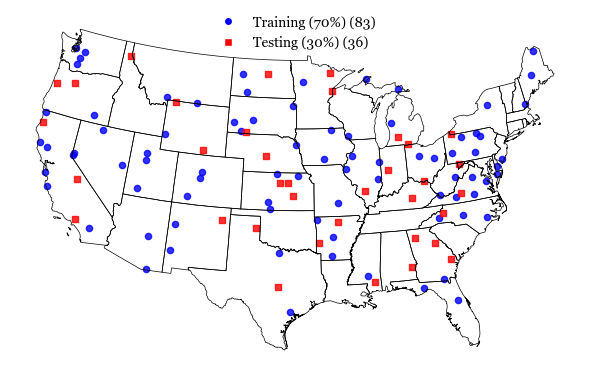

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

plt.rcParams['font.family'] = 'Georgia'

# ==============================
# 1. PREPARE DATA
# ==============================
df = basins.copy()

df['geometry_points'] = df['geometry'].centroid
df = df.set_geometry('geometry_points')
df = df.drop(columns=['geometry'])

df['gauge_lat'] = df['geometry_points'].apply(lambda x: x.y)
df['gauge_lon'] = df['geometry_points'].apply(lambda x: x.x)

# ==============================
# 2. CREATE SPATIAL BINS
# ==============================
df['lat_bin'] = pd.qcut(df['gauge_lat'], q=12, duplicates='drop').astype(str)
df['lon_bin'] = pd.qcut(df['gauge_lon'], q=12, duplicates='drop').astype(str)

df['spatial_bin'] = df['lat_bin'] + "_" + df['lon_bin']

# ==============================
# 3. SELECT EXACTLY 50 BASINS
# ==============================
selected = []

# at least one per spatial bin
for _, group in df.groupby('spatial_bin'):
    selected.append(group.sample(n=1, random_state=42))

selected_df = pd.concat(selected)

# fill remaining to reach 50
remaining_needed = 50 - len(selected_df)

if remaining_needed > 0:
    remaining_pool = df.drop(index=selected_df.index)
    additional = remaining_pool.sample(n=remaining_needed, random_state=42)
    selected_df = pd.concat([selected_df, additional])

# ==============================
# 4. TRAIN / TEST SPLIT (NO STRATIFY)
# ==============================
train_df, test_df = train_test_split(
    selected_df,
    test_size=0.3,
    random_state=42
)

# ==============================
# 5. PRINT SUMMARY
# ==============================
print(f"Total selected basins: {len(selected_df)}")
print(f"Training set: {train_df.shape}")
print(f"Testing set: {test_df.shape}")

# ==============================
# 6. PLOT
# ==============================
fig, ax = plt.subplots(figsize=(6, 4))#, dpi=300)

train_df.to_crs(5070).plot(
    ax=ax,
    color='blue',
    markersize=20,
    alpha=0.8,
    marker='o'
)

test_df.to_crs(5070).plot(
    ax=ax,
    color='red',
    markersize=25,
    alpha=0.8,
    marker='s'
)

ax.set_axis_off()

handles = [
    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor='blue', markersize=6,
               label=f'Training (70%) ({len(train_df)})'),
    plt.Line2D([0], [0], marker='s', color='w',
               markerfacecolor='red', markersize=6,
               label=f'Testing (30%) ({len(test_df)})')
]
states.boundary.to_crs(5070).plot(ax=ax, edgecolor='black', linewidth=0.5)
ax.legend(handles=handles, loc='upper center', frameon=False, bbox_to_anchor=(0.5, 1.03))

plt.tight_layout()
plt.show()

Total selected basins: 670
Training set: (469, 64)
Testing set: (201, 64)


C:\Users\hdagne1\AppData\Local\Temp\ipykernel_29188\3626023287.py:19: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  df['geometry_points'] = df['geometry'].centroid


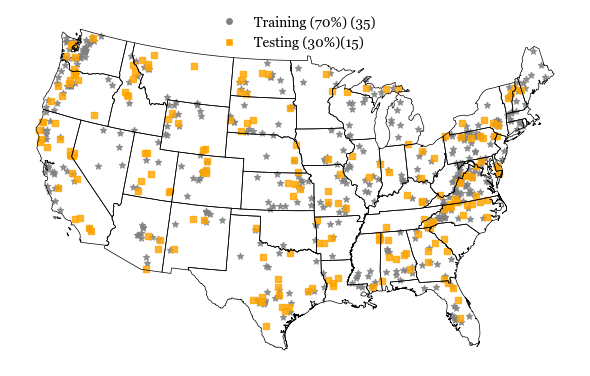

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

plt.rcParams['font.family'] = 'Georgia'

# ==============================
# 1. SETTINGS (CHANGE HERE)
# ==============================
N_BASINS = 670    # total basins to select
LAT_BINS = 4      # increase for finer spatial distribution
LON_BINS = 2    # increase for finer spatial distribution

# ==============================
# 2. PREPARE DATA
# ==============================
df = basins.copy()

df['geometry_points'] = df['geometry'].centroid
df = df.set_geometry('geometry_points')
df = df.drop(columns=['geometry'])

df['gauge_lat'] = df['geometry_points'].apply(lambda x: x.y)
df['gauge_lon'] = df['geometry_points'].apply(lambda x: x.x)

# ==============================
# 3. CREATE SPATIAL BINS
# ==============================
df['lat_bin'] = pd.qcut(df['gauge_lat'], q=LAT_BINS, duplicates='drop').astype(str)
df['lon_bin'] = pd.qcut(df['gauge_lon'], q=LON_BINS, duplicates='drop').astype(str)

df['spatial_bin'] = df['lat_bin'] + "_" + df['lon_bin']

# ==============================
# 4. SELECT BASINS (UNIFORM SPATIAL DISTRIBUTION)
# ==============================
groups = list(df.groupby('spatial_bin'))

selected = []

# number of basins per bin
n_per_bin = max(1, N_BASINS // len(groups))

for _, group in groups:
    n = min(n_per_bin, len(group))
    selected.append(group.sample(n=n, random_state=42))

selected_df = pd.concat(selected)

# fill remaining to reach exactly N_BASINS
remaining_needed = N_BASINS - len(selected_df)

if remaining_needed > 0:
    remaining_pool = df.drop(index=selected_df.index)
    additional = remaining_pool.sample(n=remaining_needed, random_state=42)
    selected_df = pd.concat([selected_df, additional])

# ==============================
# 5. TRAIN / TEST SPLIT
# ==============================
train_df, test_df = train_test_split(
    selected_df,
    test_size=0.3,
    random_state=42
)

# ==============================
# 6. PRINT SUMMARY
# ==============================
print(f"Total selected basins: {len(selected_df)}")
print(f"Training set: {train_df.shape}")
print(f"Testing set: {test_df.shape}")

# ==============================
# 7. PLOT
# ==============================
fig, ax = plt.subplots(figsize=(6, 4))#, dpi=300)

train_df.to_crs(5070).plot(
    ax=ax,
    color='gray',
    markersize=20,
    alpha=0.8,
    marker='*'
)

test_df.to_crs(5070).plot(
    ax=ax,
    color='orange',
    markersize=25,
    alpha=0.8,
    marker='s'
)

ax.set_axis_off()

handles = [
    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor='gray', markersize=6,
               label=f'Training (70%) (35)'),
    plt.Line2D([0], [0], marker='s', color='w',
               markerfacecolor='orange', markersize=6,
               label=f'Testing (30%)(15)')
]
states.boundary.to_crs(5070).plot(ax=ax, edgecolor='black', linewidth=0.5)
ax.legend(handles=handles, loc='upper center', frameon=False, bbox_to_anchor=(0.5, 1.03))

plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(3,3), dpi=300)

plt.hist(train_df['aridity'], bins=15, alpha=0.6, label='Train', color='gray')
plt.hist(test_df['aridity'], bins=15, alpha=0.6, label='Test', color='orange')

plt.xlabel('Aridity')
plt.ylabel('Count')   # now correct
plt.legend()
plt.xlim(0, 3)

plt.tight_layout()
plt.show()

# # ==============================
# # 3. KDE PLOT (smooth distribution)
# # ==============================
# plt.figure(figsize=(6,4), dpi=300)

# train_df['aridity'].plot(kind='kde', label='Train')
# test_df['aridity'].plot(kind='kde', label='Test')

# plt.xlabel('Aridity')
# plt.ylabel('Density')
# plt.legend()
# plt.title('Aridity KDE (Train vs Test)')

# plt.tight_layout()
# plt.show()

# # ==============================
# # 4. BOXPLOT (spread + outliers)
# # ==============================
# plt.figure(figsize=(5,4), dpi=300)

# plt.boxplot(
#     [train_df['aridity'], test_df['aridity']],
#     labels=['Train', 'Test']
# )

# plt.ylabel('Aridity')
# plt.title('Aridity Boxplot')

# plt.tight_layout()
# plt.show()

# # ==============================
# # 5. OPTIONAL: ECDF (very informative)
# # ==============================
# def ecdf(data):
#     x = sorted(data)
#     y = range(1, len(x)+1)
#     y = [i/len(x) for i in y]
#     return x, y

# x_train, y_train = ecdf(train_df['aridity'])
# x_test, y_test = ecdf(test_df['aridity'])

# plt.figure(figsize=(6,4), dpi=300)

# plt.plot(x_train, y_train, label='Train')
# plt.plot(x_test, y_test, label='Test')

# plt.xlabel('Aridity')
# plt.ylabel('ECDF')
# plt.legend()
# plt.title('Aridity ECDF (Train vs Test)')

# plt.tight_layout()
# plt.show()

In [ ]:
# python src/main.py evaluate --run_dir runs/run_0305_2015_seed658666 --camels_root "F:/Data/CAMEL_SI/CAMELS_US/" --gpu -1

In [10]:
import pickle
import pandas as pd

path = r"F:\Github_repos\HydroAuditToolFrameowrk\runs\run_0305_2015_seed658666\lstm_seed658.p"

with open(path, "rb") as f:
    results = pickle.load(f)
lstm_predictions = pd.concat(results, names=["basin", "date"])


lstm_predictions = lstm_predictions.reset_index()
print(lstm_predictions['basin'].unique().shape)
lstm_predictions

negative_qsim = lstm_predictions[lstm_predictions["qsim"] < 0]

negative_qsim

(670,)


,basin,date,qobs,qsim
6878,01022500,1999-07-31,0.187341,-0.001114
6902,01022500,1999-08-24,0.149873,-0.002444
6903,01022500,1999-08-25,0.137384,-0.010741
6904,01022500,1999-08-26,0.129057,-0.010632
6907,01022500,1999-08-29,0.120731,-0.012803
...,...,...,...,...
3665446,14362250,2010-09-26,0.007678,-0.087039
3665447,14362250,2010-09-27,0.006497,-0.103044
3665448,14362250,2010-09-28,0.005316,-0.108069
3665449,14362250,2010-09-29,0.005316,-0.126070


In [11]:
lstm_predictions

,basin,date,qobs,qsim
0,01013500,1995-10-01,0.051961,0.166915
1,01013500,1995-10-02,0.049796,0.140504
2,01013500,1995-10-03,0.046548,0.146489
3,01013500,1995-10-04,0.045465,0.194881
4,01013500,1995-10-05,0.045465,0.203668
...,...,...,...,...
3670925,14400000,2010-09-26,0.470772,0.479822
3670926,14400000,2010-09-27,0.449849,0.402811
3670927,14400000,2010-09-28,0.432413,0.338965
3670928,14400000,2010-09-29,0.414977,0.315340


In [22]:

# path = r"C:\Users\hdagne1\Box\NRT_Project_2026_Spring\Habtamu\HydroAuditToolFrameowrk\runs\run_0305_2015_seed658666\lstm_seed658666.p"

# with open(path, "rb") as f:
#     results = pickle.load(f)
# lstm_predictions = pd.concat(results, names=["basin", "date"])



In [12]:
(lstm_predictions["qsim"] < 0).sum()

np.int64(256035)

In [13]:
256035/3670930*100

6.974663096272607

In [6]:
lstm_predictions['basin'].unique().shape

(670,)

In [14]:
# import pickle
# import pandas as pd

# path = r"C:\Users\hdagne1\Box\NRT_Project_2026_Spring\Habtamu\HydroAuditToolFrameowrk\runs\run_2304_1157_seed390389\lstm_seed390389.p"

# with open(path, "rb") as f:
#     results = pickle.load(f)
# lstm_predictions = pd.concat(results, names=["basin", "date"])
# lstm_predictions = lstm_predictions.reset_index()
# lstm_predictions

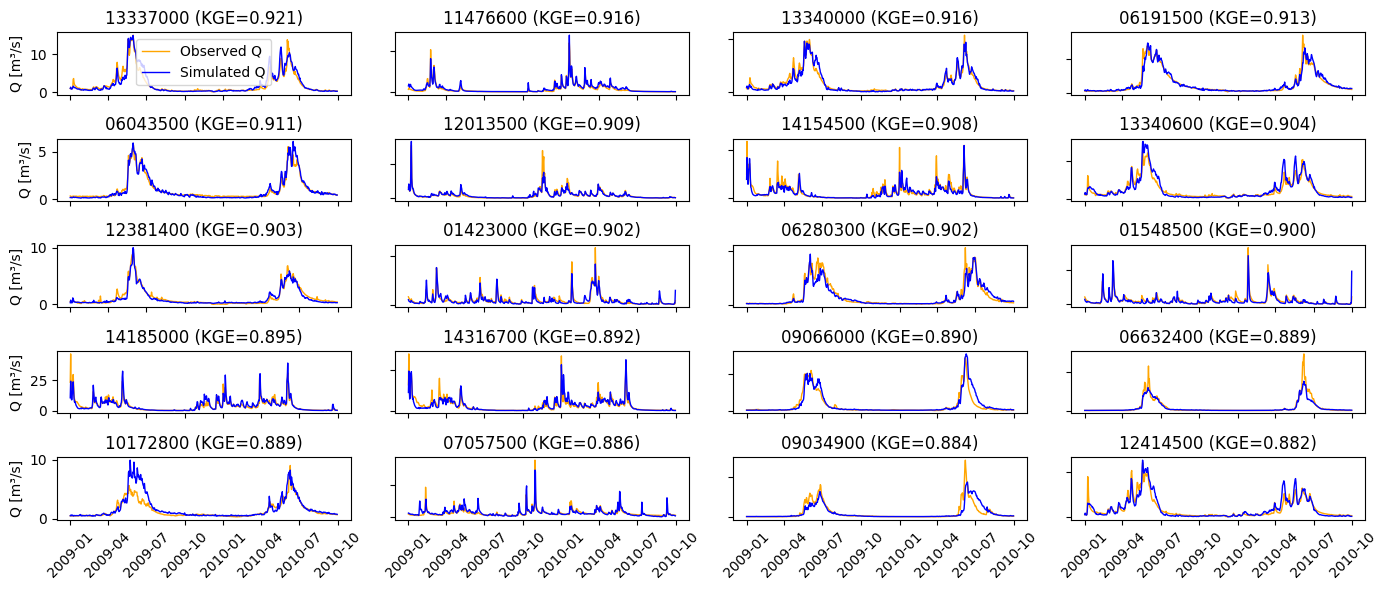

In [15]:

def NSE(obs, sim):
    obs = np.array(obs)
    sim = np.array(sim)
    return 1 - np.sum((sim - obs)**2) / np.sum((obs - np.mean(obs))**2)


def KGE(obs, sim):
    obs = np.array(obs)
    sim = np.array(sim)

    r = np.corrcoef(obs, sim)[0,1]
    alpha = np.std(sim) / np.std(obs)
    beta = np.mean(sim) / np.mean(obs)

    return 1 - np.sqrt((r-1)**2 + (alpha-1)**2 + (beta-1)**2)


def NSE(obs, sim):
    obs = np.array(obs)
    sim = np.array(sim)
    return 1 - np.sum((sim - obs)**2) / np.sum((obs - np.mean(obs))**2)


def KGE(obs, sim):
    obs = np.array(obs)
    sim = np.array(sim)

    r = np.corrcoef(obs, sim)[0,1]
    alpha = np.std(sim) / np.std(obs)
    beta = np.mean(sim) / np.mean(obs)

    return 1 - np.sqrt((r-1)**2 + (alpha-1)**2 + (beta-1)**2)

df = lstm_predictions.copy()
df["date"] = pd.to_datetime(df["date"])

def KGE(obs, sim):
    r = np.corrcoef(obs, sim)[0,1]
    alpha = np.std(sim) / np.std(obs)
    beta = np.mean(sim) / np.mean(obs)
    return 1 - np.sqrt((r-1)**2 + (alpha-1)**2 + (beta-1)**2)


# compute KGE using full record
kge_scores = []

for basin, d in df.groupby("basin"):
    obs = d["qobs"].values
    sim = d["qsim"].values
    kge = KGE(obs, sim)
    kge_scores.append((basin, kge))

kge_df = pd.DataFrame(kge_scores, columns=["basin","KGE"])
nse = NSE(d["qobs"], d["qsim"])


# select best 6 basins
top3 = kge_df.sort_values("KGE", ascending=False).head(20)["basin"]

fig, axes = plt.subplots(5, 4, figsize=(14, 6), sharex=False, sharey=False)
axes = axes.flatten()

for i, basin in enumerate(top3):

    d = df[df["basin"] == basin]
    kge = KGE(d["qobs"], d["qsim"])
    d_plot = d[(d["date"] >= "2009-01-01") & (d["date"] <= "2010-12-31")]

    ax = axes[i]

    ax.plot(d_plot["date"], d_plot["qobs"], label="Observed Q", linewidth=1, c='orange')
    ax.plot(d_plot["date"], d_plot["qsim"], label="Simulated Q", linewidth=1, c='blue')

    ax.set_title(f"{basin} (KGE={kge:.3f})")

    # ✅ X-axis: only last row (indices 16–19)
    if i < 16:
        ax.set_xticklabels([])
    else:
        ax.tick_params(axis='x', rotation=45)

    # ✅ Y-axis: only first column (i % 4 == 0)
    if i % 4 != 0:
        ax.set_yticklabels([])
    else:
        ax.set_ylabel("Q [m³/s]")

    if i == 0:
        ax.legend()
plt.tight_layout()